# Building Energy Consumption Prediction

**A Machine Learning Regression Project**

## Project Overview

Buildings consume energy through multiple interacting factors, including environmental conditions, occupancy, building size, and the operation of systems such as heating, ventilation, air conditioning (HVAC), and lighting. Understanding how these factors relate to energy use can support better analysis of building energy behavior.

This project develops and evaluates machine learning regression models to predict a building's total energy consumption from a set of environmental, physical, and operational features.

## Project Objectives

- Explore and understand the building energy dataset.
- Prepare numerical and categorical variables for machine learning.
- Investigate relationships between the input features and the energy-consumption target.
- Create additional features that represent selected nonlinear effects and interactions.
- Train and compare several regression algorithms.
- Apply cross-validation and hyperparameter search to assess model performance.
- Evaluate the selected model on a held-out test set and save the resulting artifacts.

**Problem Type:** Supervised Learning — Regression  
**Target Variable:** `Energy` (derived from `EnergyConsumption`)

> **Dataset note:** The Kaggle dataset describes hypothetical timestamp-based environments and identifies the data as synthetic. Therefore, the results in this project should be interpreted as an experiment on simulated data, not as evidence of performance on measured buildings in the real world.

**Dataset source:** [Energy Consumption Prediction — Kaggle](https://www.kaggle.com/datasets/mrsimple07/energy-consumption-prediction)


In [49]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy import stats
import joblib
import json
from datetime import datetime
import os
import time

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    PolynomialFeatures
)
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import (
    SelectKBest,
    f_regression,
    RFE)
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    VotingRegressor     
)
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_squared_error,
    r2_score, 
    mean_absolute_error
)
from sklearn.inspection import (
    permutation_importance,      
    PartialDependenceDisplay
)

import mlflow
import mlflow.sklearn
from mlflow.models.signature import infer_signature


## Configuration and Reproducibility

Before exploring and training models, we define a centralized configuration for the experiment. Keeping these settings together makes the workflow easier to reproduce and maintain.

### Main configuration settings

- **`RANDOM_STATE = 42`**: fixes the random seed used by supported randomized operations, helping make repeated runs more consistent.
- **`TEST_SIZE = 0.2`**: reserves 20% of the dataset for the test partition in the later split.
- **`VAL_SIZE = 0.2`**: reserves 20% of the temporary training portion for validation.
- **`CV_FOLDS = 5`**: uses five folds for cross-validation.
- **`N_JOBS = -1`**: allows supported scikit-learn operations to use all available CPU cores.

### Project directories

- **`MODEL_DIR`** stores exported model-related files.
- **`EXPERIMENT_DIR`** stores MLflow experiment-tracking data.
- **`os.makedirs(..., exist_ok=True)`** creates the directories when they do not already exist.

### MLflow tracking

MLflow is used to record experiment information such as model parameters, evaluation metrics, and model artifacts. This makes it easier to review and compare experiments after training.


In [50]:
import os
import mlflow

class Config:
    # Reproducibility - Critical for production!
    RANDOM_STATE = 42
    TEST_SIZE = 0.2
    VAL_SIZE = 0.2
    CV_FOLDS = 5
    N_JOBS = -1

    # Model directories
    MODEL_DIR = "models"
    EXPERIMENT_DIR = "experiments"

    # Create directories if they don't exist
    os.makedirs(MODEL_DIR, exist_ok=True)
    os.makedirs(EXPERIMENT_DIR, exist_ok=True)


config = Config()

# Initialize MLflow using SQLite
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Set experiment name
experiment_name = "california_housing_advanced"

mlflow.set_experiment(experiment_name)

print("MLflow initialized successfully!")
print("Tracking URI:", mlflow.get_tracking_uri())

MLflow initialized successfully!
Tracking URI: sqlite:///mlflow.db


## Step 1 — Loading the Dataset

The first step is to load the Kaggle dataset into a pandas DataFrame. A copy is created so that subsequent preparation steps can be applied without modifying the original loaded object.

The code then:
- Creates `Energy` as the target column by copying the values from `EnergyConsumption`.
- Removes `Timestamp`, `DayOfWeek`, and the original `EnergyConsumption` column from the working feature table.
- Converts `Occupancy` to a floating-point numeric type.

The resulting DataFrame contains the predictors used in this notebook together with the target variable.


In [51]:
dff = pd.read_csv(r"C:\Assjad Hatim\project-1\SAIR_Jr\1_Regression\Regression Capstone Projects\Assjad Elniema\data\Energy_consumption.csv")
df = dff.copy()
df['Energy'] = df.EnergyConsumption  # Target variable
df.drop(columns=["Timestamp","DayOfWeek","EnergyConsumption"], inplace=True)
df["Occupancy"] = df["Occupancy"].astype(float)

print(f" Dataset loaded successfully!")



 Dataset loaded successfully!


### Initial Dataset Statistics

We begin by examining descriptive statistics for the numerical columns. Measures such as the mean, standard deviation, minimum, quartiles, and maximum provide an initial understanding of each variable's scale and spread.

This inspection is useful for identifying unusually wide value ranges and understanding the general magnitude of the target before applying transformations.


In [52]:
print("DATASET STATISTICS")
print(df.describe())



DATASET STATISTICS
       Temperature     Humidity  SquareFootage    Occupancy  RenewableEnergy  \
count  1000.000000  1000.000000    1000.000000  1000.000000      1000.000000   
mean     24.982026    45.395412    1500.052488     4.581000        15.132813   
std       2.836850     8.518905     288.418873     2.865598         8.745917   
min      20.007565    30.015975    1000.512661     0.000000         0.006642   
25%      22.645070    38.297722    1247.108548     2.000000         7.628385   
50%      24.751637    45.972116    1507.967426     5.000000        15.072296   
75%      27.418174    52.420066    1740.340165     7.000000        22.884064   
max      29.998671    59.969085    1999.982252     9.000000        29.965327   

            Energy  
count  1000.000000  
mean     77.055873  
std       8.144112  
min      53.263278  
25%      71.544690  
50%      76.943696  
75%      82.921742  
max      99.201120  


### Missing Values Check

Missing values can affect many machine learning algorithms and may require an explicit treatment strategy.

We check the number of missing entries in every column. The displayed output indicates that no missing values are present in the working dataset, so no imputation step is required at this stage.


In [53]:
print("MISSING VALUES CHECK")
print(df.isnull().sum())


MISSING VALUES CHECK
Temperature        0
Humidity           0
SquareFootage      0
Occupancy          0
HVACUsage          0
LightingUsage      0
RenewableEnergy    0
Holiday            0
Energy             0
dtype: int64


### Data Type Inspection

We inspect each column's data type to distinguish numerical variables from categorical variables.

This distinction matters because categorical values must be represented numerically before they can be used by most regression estimators. The next step handles the categorical features using one-hot encoding.


In [54]:
print("DATA TYPES")
print(df.dtypes)

DATA TYPES
Temperature        float64
Humidity           float64
SquareFootage      float64
Occupancy          float64
HVACUsage              str
LightingUsage          str
RenewableEnergy    float64
Holiday                str
Energy             float64
dtype: object


### Encoding Categorical Features

The dataset contains categorical variables describing whether a record falls on a holiday and whether HVAC and lighting systems are in use.

`OneHotEncoder` converts these categories into numerical indicator columns. With `drop='first'`, one category from each variable is omitted to provide a reference category and avoid redundant indicator columns in models that use an intercept.

The resulting columns include:
- `Holiday_Yes`
- `HVACUsage_On`
- `LightingUsage_On`

The encoded columns are converted to floating-point values so that they can be used consistently in the numerical preprocessing workflow.


In [55]:
from sklearn.preprocessing import OneHotEncoder

df_encoded = df.copy()

categorical_cols = ['Holiday', 'HVACUsage', 'LightingUsage']

encoder = OneHotEncoder(
    drop='first',
    sparse_output=False,
    handle_unknown='ignore',
    dtype=int
)

encoded_data = encoder.fit_transform(df_encoded[categorical_cols])

encoded_cols = encoder.get_feature_names_out(categorical_cols)

df_encoded = df_encoded.drop(columns=categorical_cols)

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoded_cols,
    index=df.index
)

df_encoded = pd.concat([df_encoded, encoded_df], axis=1)
df = df_encoded.copy()
df['Holiday_Yes'] = df['Holiday_Yes'].astype(float)
df['HVACUsage_On'] = df['HVACUsage_On'].astype(float)
df['LightingUsage_On'] = df['LightingUsage_On'].astype(float)
print(df_encoded.head())
print(df_encoded.shape)

   Temperature   Humidity  SquareFootage  Occupancy  RenewableEnergy  \
0    25.139433  43.431581    1565.693999        5.0         2.774699   
1    27.731651  54.225919    1411.064918        1.0        21.831384   
2    28.704277  58.907658    1755.715009        2.0         6.764672   
3    20.080469  50.371637    1452.316318        1.0         8.623447   
4    23.097359  51.401421    1094.130359        9.0         3.071969   

      Energy  Holiday_Yes  HVACUsage_On  LightingUsage_On  
0  75.364373            0             1                 0  
1  83.401855            0             1                 1  
2  78.270888            0             0                 0  
3  56.519850            0             0                 1  
4  70.811732            0             1                 0  
(1000, 9)


In [56]:
print("NOW DATA TYPES")
print(df.dtypes)

NOW DATA TYPES
Temperature         float64
Humidity            float64
SquareFootage       float64
Occupancy           float64
RenewableEnergy     float64
Energy              float64
Holiday_Yes         float64
HVACUsage_On        float64
LightingUsage_On    float64
dtype: object


## Step 2 — Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset before building predictive models. In this section, we examine the distributions of the available numerical variables using histograms.

The histograms help reveal:
- The range and concentration of values.
- Whether a variable is approximately symmetric or skewed.
- Whether values appear concentrated around particular intervals.
- Potentially unusual observations that may deserve further investigation.

EDA provides context for later preprocessing and feature-engineering decisions; it does not, by itself, establish causal relationships.


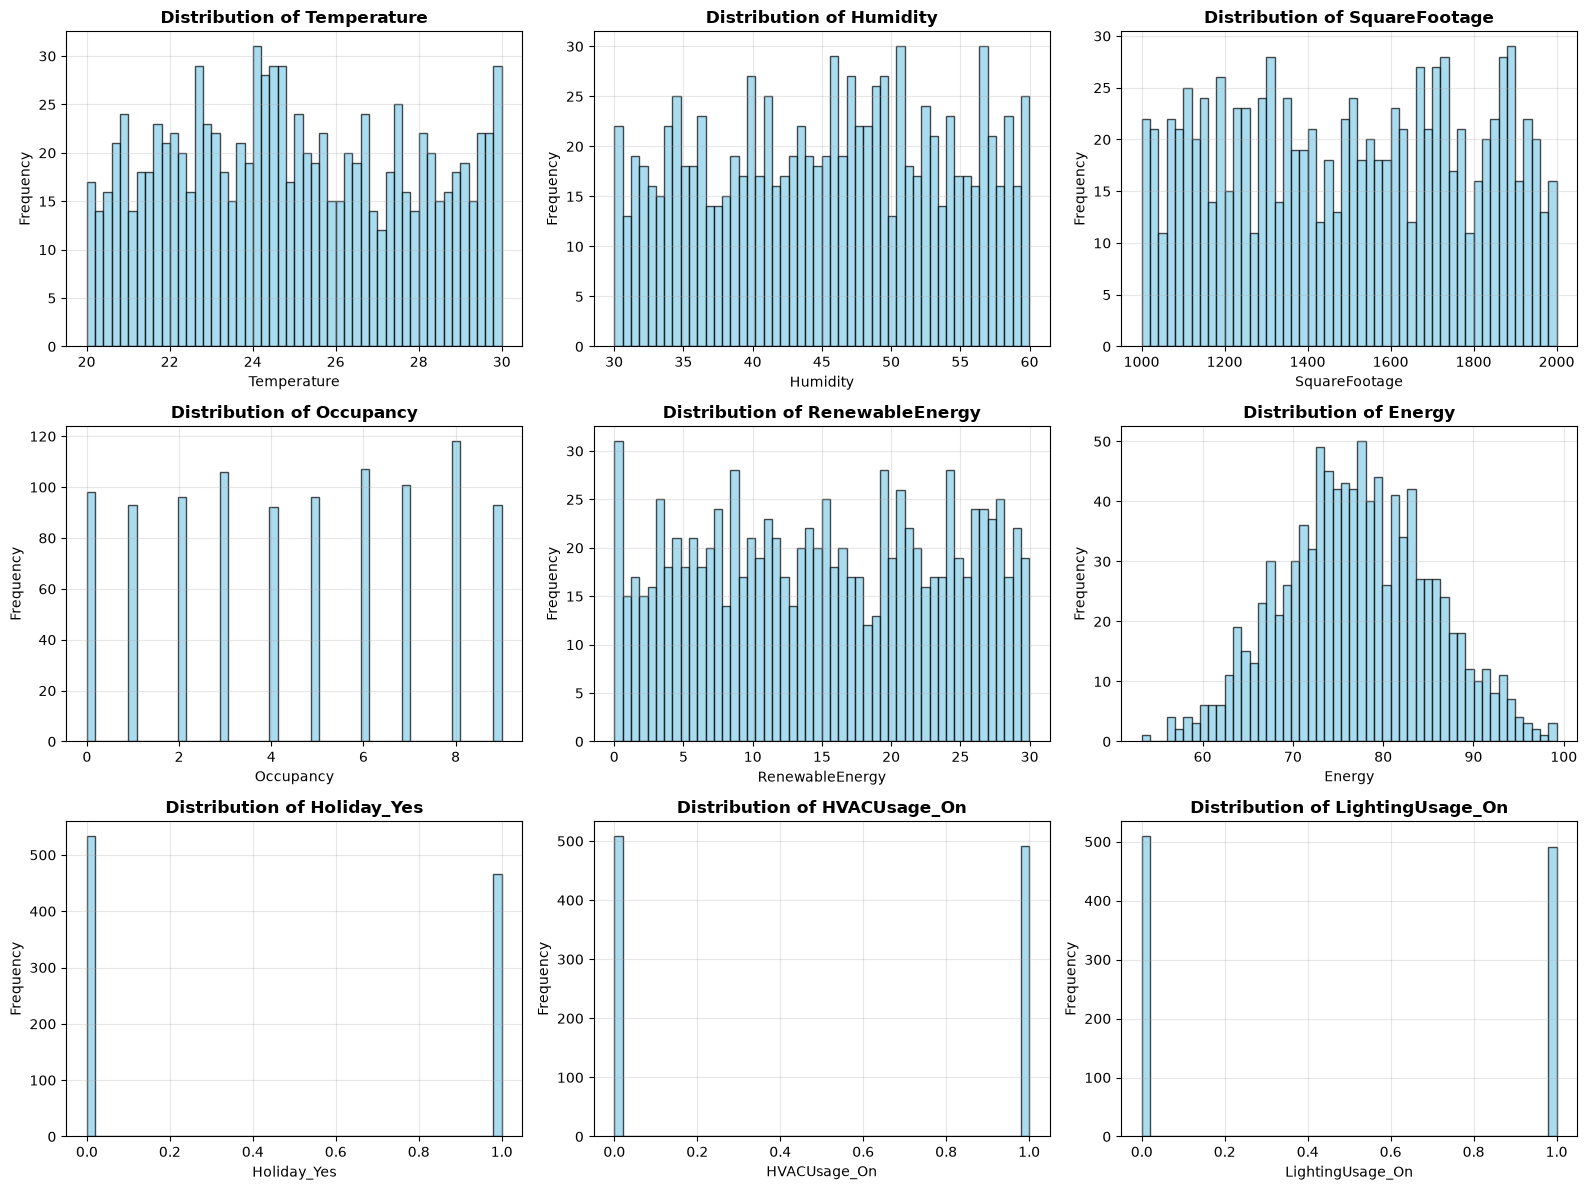

In [57]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.ravel()

for idx, col in enumerate(df.columns):
    axes[idx].hist(df[col], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
    axes[idx].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Frequency')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Correlation Analysis

A correlation matrix provides a compact view of the strength and direction of linear relationships between numerical variables.

The heatmap is used for two main purposes:

1. **Feature-to-target relationships:** to identify which predictors have stronger positive or negative linear associations with `Energy`.
2. **Feature-to-feature relationships:** to identify pairs of predictors that may contain overlapping linear information.

Correlation is a measure of association, not proof of causation. A weak linear correlation also does not necessarily mean that a feature has no predictive value, because its relationship with energy consumption may be nonlinear or depend on interactions with other variables.


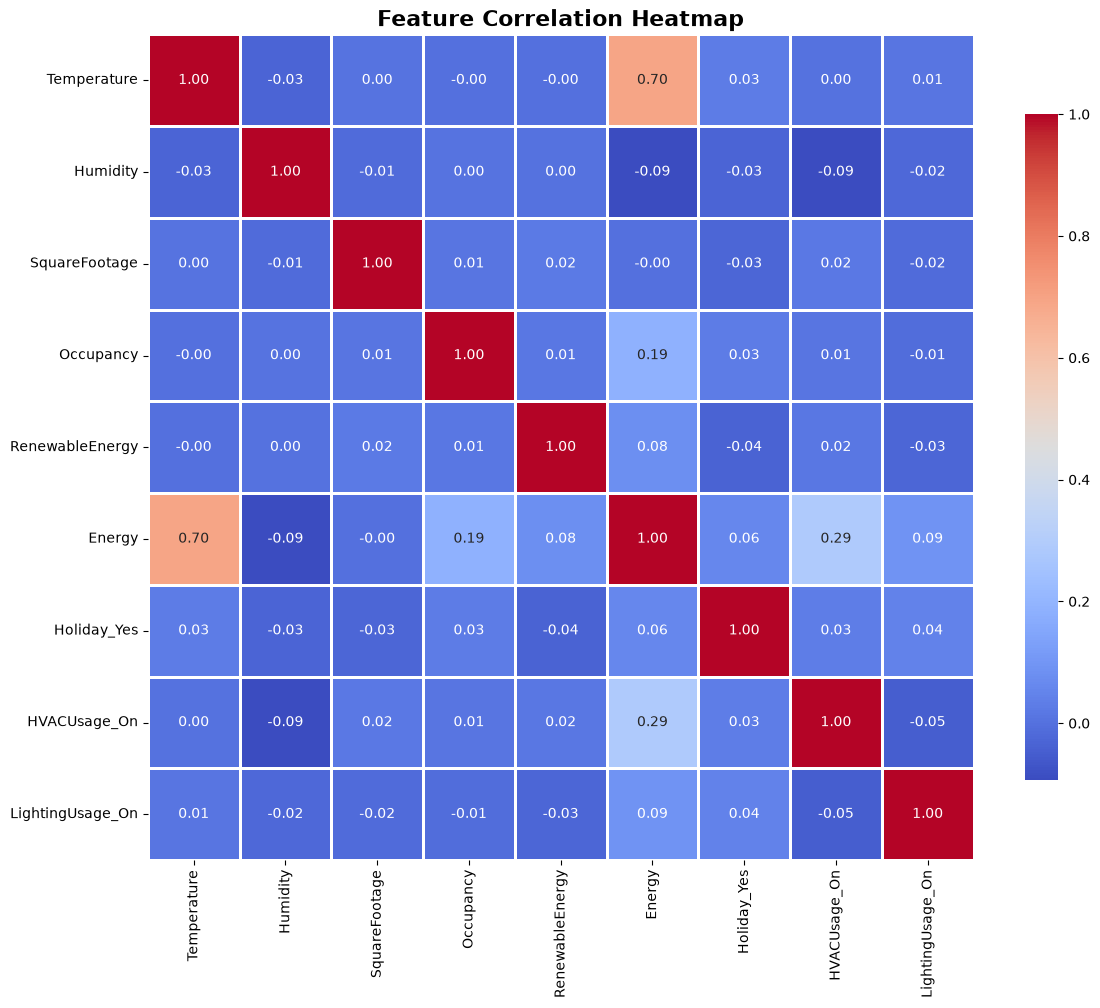


🎯 FEATURES RANKED BY CORRELATION WITH PRICE
Temperature       0.6964
HVACUsage_On      0.2865
Occupancy         0.1866
LightingUsage_On   0.0934
RenewableEnergy   0.0812
Holiday_Yes       0.0567
SquareFootage    -0.0011
Humidity         -0.0936


In [58]:
import seaborn as sns

# Correlation matrix
correlation_matrix = df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Heatmap', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Feature importance ranking
print("\n" + "=" * 70)
print("🎯 FEATURES RANKED BY CORRELATION WITH PRICE")
print("=" * 70)
correlations = correlation_matrix['Energy'].drop('Energy').sort_values(ascending=False)
for feature, corr in correlations.items():
    print(f"{feature:<15} {corr:>8.4f}")

### Interpreting Feature Correlations

The printed ranking orders the predictors by their correlation with the target variable, `Energy`.

In the current dataset output, `Temperature` has the strongest positive linear correlation with energy consumption. `HVACUsage_On` and `Occupancy` also show positive correlations, while `Humidity` has a weak negative correlation.

These values provide an initial statistical overview only. They should not be treated as definitive feature-importance scores, and they do not account for nonlinear effects or interactions between predictors.


In [59]:
print("FEATURES RANKED BY CORRELATION WITH ENERGY")
correlations = correlation_matrix['Energy'].drop('Energy').sort_values(ascending=False)
for feature, corr in correlations.items():
    print(f"{feature:<15} {corr:>8.4f}")

FEATURES RANKED BY CORRELATION WITH ENERGY
Temperature       0.6964
HVACUsage_On      0.2865
Occupancy         0.1866
LightingUsage_On   0.0934
RenewableEnergy   0.0812
Holiday_Yes       0.0567
SquareFootage    -0.0011
Humidity         -0.0936


## Step 3 — Separating Features and Target

For supervised regression, we separate the dataset into:

- **`X` (Features):** the input variables used by the model to make predictions.
- **`y` (Target):** the variable the model is trained to predict, which is `Energy` in this project.

Keeping the predictors and target separate makes the subsequent splitting, preprocessing, training, and evaluation steps explicit.


### Initial Train–Test Split

We first create a training set and a held-out test set using an 80/20 split.

- **Training set:** used to fit the initial scaler and train models in the initial workflow.
- **Test set:** reserved for evaluation after model development.

The fixed random state makes the split reproducible. The notebook later introduces a separate validation set for model comparison and hyperparameter selection.


In [60]:
X = df.drop('Energy', axis=1)
y = df['Energy']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("DATA SPLIT")
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples:  {X_test.shape[0]}")
print(f"Number of features: {X_train.shape[1]}")

DATA SPLIT
Training samples: 800
Testing samples:  200
Number of features: 8


### Feature Scaling with StandardScaler

The predictors have different units and numerical ranges. For example, temperature, humidity, building area, and occupancy are measured on very different scales.

`StandardScaler` standardizes each feature using statistics calculated from the training data:

\[
z = \frac{x - \mu_{train}}{\sigma_{train}}
\]

where \(\mu_{train}\) and \(\sigma_{train}\) are the training-set mean and standard deviation.

The scaler is fitted on `X_train` and then applied to both training and test data. This is the appropriate fit/transform pattern for this initial scaling step because the test data does not contribute to the scaler's learned statistics.


In [61]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train) 
X_test_scaled = scaler.transform(X_test)

print("FEATURE SCALING APPLIED")
print("\nBefore scaling (first sample):")
print(X_train.iloc[0].values)
print("\nAfter scaling (first sample):")
print(X_train_scaled[0])

FEATURE SCALING APPLIED

Before scaling (first sample):
[2.32206299e+01 4.60738794e+01 1.64951035e+03 2.00000000e+00
 1.82705282e+01 0.00000000e+00 0.00000000e+00 1.00000000e+00]

After scaling (first sample):
[-0.60007123  0.11723233  0.51063898 -0.93096815  0.33478968 -0.90911166
 -1.00752834  1.02532046]


### Visualizing the Effect of Scaling

The boxplots compare the feature ranges before and after standardization.

After scaling, the features are expressed on a more comparable scale. This is particularly useful for algorithms whose behavior is influenced by feature magnitude or distance, such as Support Vector Regression and regularized linear models.

Scaling changes the representation of the input features; it does not change the target variable.


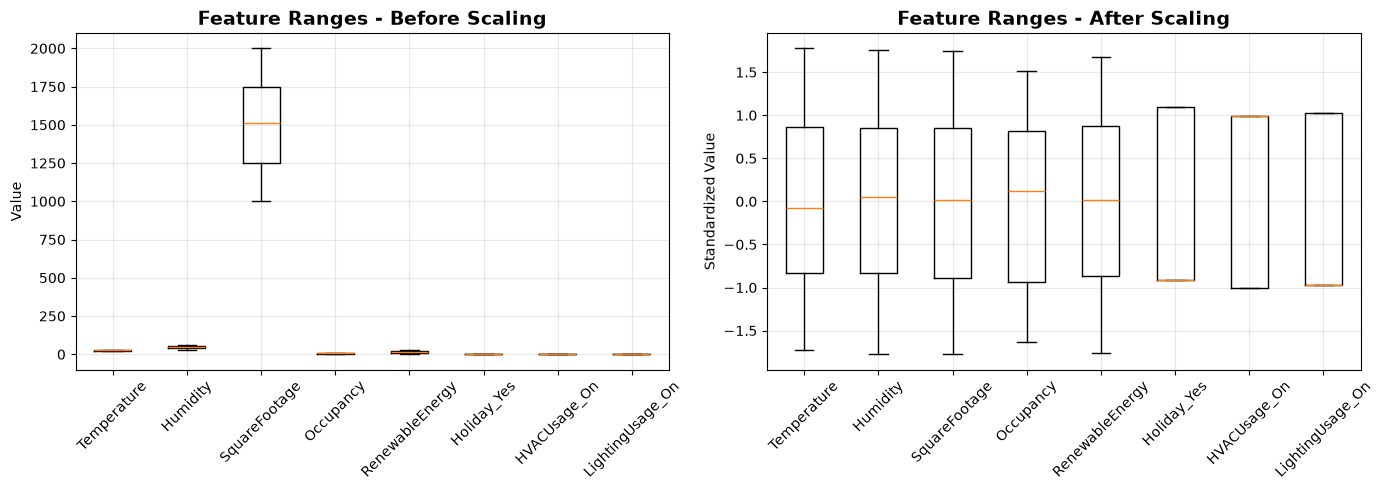

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before scaling
axes[0].boxplot(X_train.values, tick_labels=X_train.columns)
axes[0].set_title('Feature Ranges - Before Scaling', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Value')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3)

# After scaling
axes[1].boxplot(X_train_scaled, tick_labels=X_train.columns)
axes[1].set_title('Feature Ranges - After Scaling', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Standardized Value')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Step 4 — Advanced Feature Engineering

Feature engineering creates additional predictors from existing variables to represent relationships that may not be captured easily by the original columns alone.

This notebook defines a custom scikit-learn-compatible transformer, `AdvancedFeatureEngineer`. It retains the original input columns and adds eight engineered features.

### Features created by the transformer

| Engineered feature | Construction | Intended representation |
|---|---|---|
| `Temperature_squared` | Temperature² | Allows a nonlinear temperature relationship. |
| `Temperature_HVAC` | Temperature × HVAC usage indicator | Represents an interaction between temperature and HVAC operation. |
| `Temperature_abs_diff` | |Temperature − 22| | Measures the distance from a chosen 22-degree reference point. |
| `Occupancy_Lighting` | Occupancy × lighting indicator | Represents occupancy when lighting is active. |
| `Occupancy_HVAC` | Occupancy × HVAC indicator | Represents occupancy when HVAC is active. |
| `SquareFootage_Occupancy` | Building area × occupancy | Combines building size and occupancy into one interaction term. |
| `Humidity_squared` | Humidity² | Allows a nonlinear humidity relationship. |
| `log_SquareFootage` | log(1 + building area) | Compresses the scale of building-area values. |

### Why use a custom transformer?

Implementing feature engineering as a transformer makes the operations reusable and compatible with scikit-learn pipelines. The same feature definitions can therefore be applied consistently whenever the transformer is called.

These features are hypotheses about potentially useful relationships. Their usefulness must be assessed through model evaluation rather than assumed in advance.


In [63]:

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin


class AdvancedFeatureEngineer(BaseEstimator, TransformerMixin):
    """Create domain-informed features for energy consumption prediction."""

    def __init__(self):
        self.feature_names = None
        self.original_feature_names = None

    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("X must be a pandas DataFrame.")

        required_columns = [
            "Temperature",
            "Humidity",
            "SquareFootage",
            "Occupancy",
            "RenewableEnergy",
            "HVACUsage_On",
            "LightingUsage_On"
        ]

        missing = [col for col in required_columns if col not in X.columns]
        if missing:
            raise ValueError(f"Missing required columns: {missing}")

        self.original_feature_names = list(X.columns)

        self.feature_names = (
            self.original_feature_names
            + [
                "Temperature_squared",
                "Temperature_HVAC",
                "Temperature_abs_diff",
                "Occupancy_Lighting",
                "Occupancy_HVAC",
                "SquareFootage_Occupancy",
                "Humidity_squared",
                "log_SquareFootage"
            ]
        )

        return self

    def transform(self, X):
        X_eng = X.copy()

        # Non-linear temperature effect
        X_eng["Temperature_squared"] = (
            X_eng["Temperature"] ** 2
        )

        # Interaction between temperature and HVAC usage
        X_eng["Temperature_HVAC"] = (
            X_eng["Temperature"] * X_eng["HVACUsage_On"]
        )

        # Temperature distance from a reference point
        X_eng["Temperature_abs_diff"] = (
            X_eng["Temperature"] - 22
        ).abs()

        # Interaction between occupancy and lighting
        X_eng["Occupancy_Lighting"] = (
            X_eng["Occupancy"] * X_eng["LightingUsage_On"]
        )

        # Interaction between occupancy and HVAC
        X_eng["Occupancy_HVAC"] = (
            X_eng["Occupancy"] * X_eng["HVACUsage_On"]
        )

        # Building size relative to the number of occupants
        X_eng["SquareFootage_Occupancy"] = (
            X_eng["SquareFootage"]
            * X_eng["Occupancy"]
        )

        # Non-linear humidity effect
        X_eng["Humidity_squared"] = (
            X_eng["Humidity"] ** 2
        )

        # Log transformation of building size
        X_eng["log_SquareFootage"] = np.log1p(
            X_eng["SquareFootage"].clip(lower=0)
        )

        # Replace infinite values caused by invalid inputs
        X_eng = X_eng.replace([np.inf, -np.inf], np.nan)

        return X_eng

    def get_feature_names(self):
        return self.feature_names



### Applying the Feature Engineer

We apply `AdvancedFeatureEngineer` to the training features and compare the dimensions before and after transformation.

The output confirms that the original eight predictors are expanded to sixteen columns: the original features plus eight engineered features. This check verifies that the transformer has added the expected columns.


In [64]:
feature_engineer = AdvancedFeatureEngineer()

X_train_eng = feature_engineer.fit_transform(X_train)

print("Before Feature Engineering:")
print(X_train.shape)

print("\nAfter Feature Engineering:")
print(X_train_eng.shape)

print("\nNew Features:")
print(X_train_eng.columns.tolist())

Before Feature Engineering:
(800, 8)

After Feature Engineering:
(800, 16)

New Features:
['Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'RenewableEnergy', 'Holiday_Yes', 'HVACUsage_On', 'LightingUsage_On', 'Temperature_squared', 'Temperature_HVAC', 'Temperature_abs_diff', 'Occupancy_Lighting', 'Occupancy_HVAC', 'SquareFootage_Occupancy', 'Humidity_squared', 'log_SquareFootage']


### Correlation Analysis After Feature Engineering

After creating the additional predictors, we calculate correlations between the engineered features and the target.

This analysis helps us inspect whether the new variables show linear associations with energy consumption and whether they provide different patterns from the original features.

Some engineered features are mathematically derived from existing columns, so correlation with the target should be interpreted carefully. A higher correlation does not automatically guarantee better predictive performance; the model comparison later provides a more direct assessment.


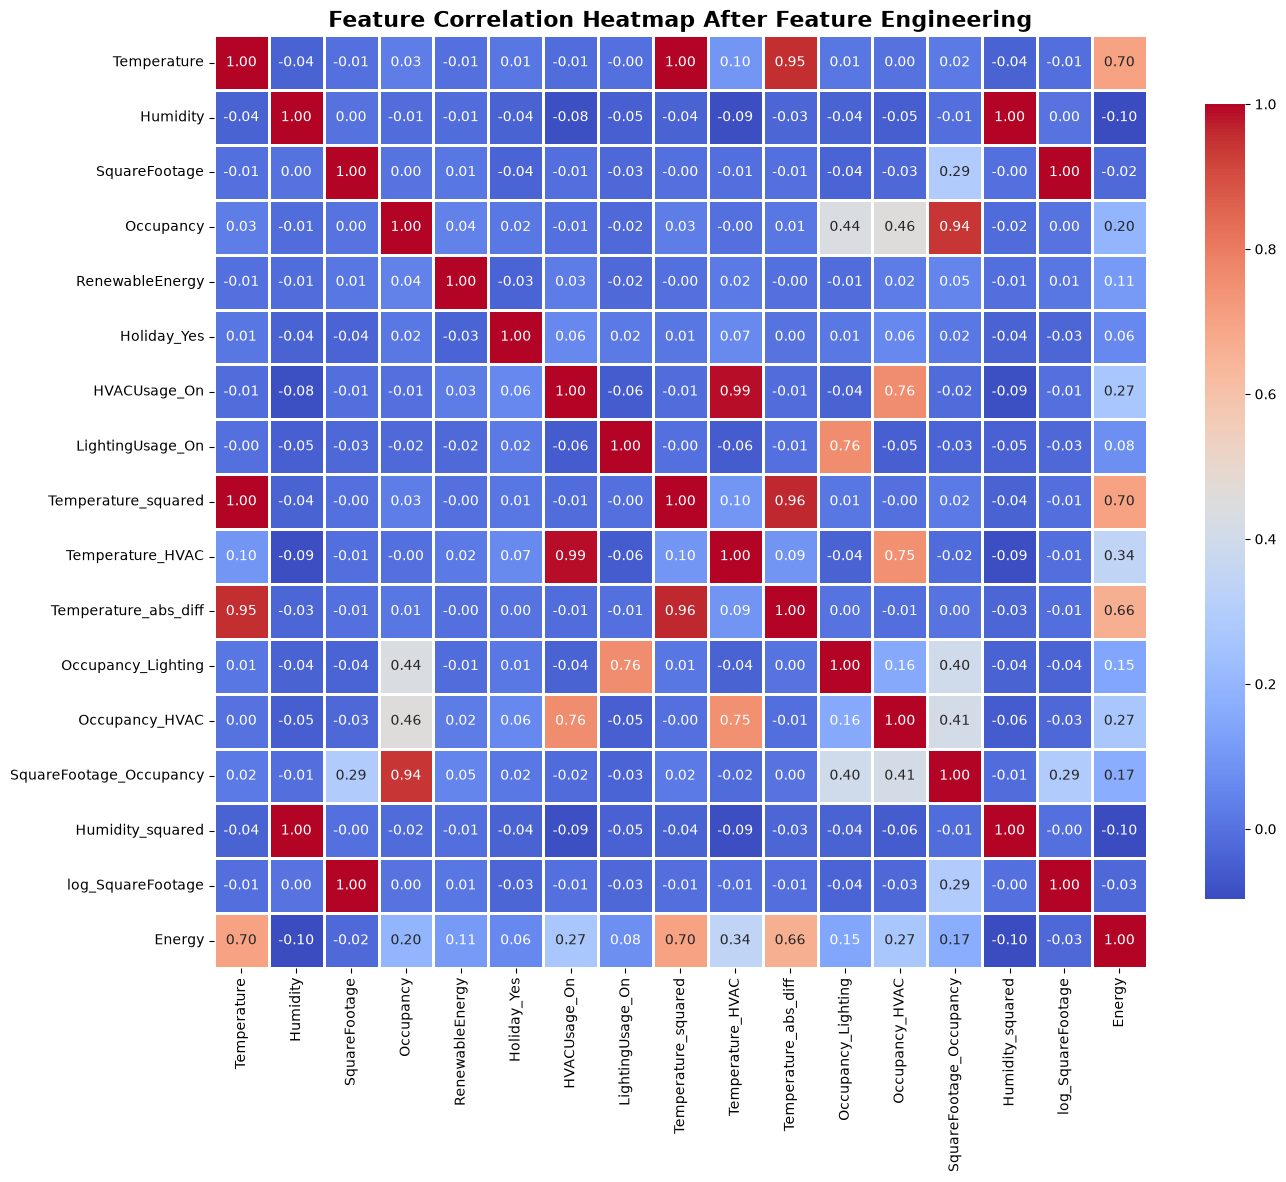


🎯 FEATURES RANKED BY CORRELATION WITH ENERGY
Temperature                 0.7019
Temperature_squared         0.7001
Temperature_abs_diff        0.6641
Temperature_HVAC            0.3432
HVACUsage_On                0.2683
Occupancy_HVAC              0.2681
Occupancy                   0.1975
SquareFootage_Occupancy     0.1725
Occupancy_Lighting          0.1469
RenewableEnergy             0.1092
LightingUsage_On            0.0786
Holiday_Yes                 0.0591
SquareFootage              -0.0230
log_SquareFootage          -0.0263
Humidity_squared           -0.0967
Humidity                   -0.0971


In [65]:
import seaborn as sns
import matplotlib.pyplot as plt

# Correlation matrix after Feature Engineering
correlation_matrix = X_train_eng.copy()

# Add target column
correlation_matrix['Energy'] = y_train.values

correlation_matrix = correlation_matrix.corr()

plt.figure(figsize=(14, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    square=True,
    linewidths=1,
    cbar_kws={"shrink": 0.8}
)

plt.title(
    'Feature Correlation Heatmap After Feature Engineering',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# Feature importance ranking
print("\n" + "=" * 70)
print("🎯 FEATURES RANKED BY CORRELATION WITH ENERGY")
print("=" * 70)

correlations = (
    correlation_matrix['Energy']
    .drop('Energy')
    .sort_values(ascending=False)
)

for feature, corr in correlations.items():
    print(f"{feature:<25} {corr:>8.4f}")

### Applying Feature Engineering to the Full Feature Table

This cell applies the same feature-engineering transformer to the complete feature table to inspect the resulting engineered dataset.

The displayed shape and feature names provide a quick verification of the transformation. The subsequent advanced preprocessing section combines feature engineering with outlier handling and robust scaling.


In [66]:
engineer = AdvancedFeatureEngineer()

X_engineered = engineer.fit_transform(X)

print("Feature engineering complete!")
print("Original features:", X.shape[1])
print("Engineered features:", X_engineered.shape[1])
print("New features:", engineer.get_feature_names()[-3:])

X_engineered.head()

Feature engineering complete!
Original features: 8
Engineered features: 16
New features: ['SquareFootage_Occupancy', 'Humidity_squared', 'log_SquareFootage']


,Temperature,Humidity,SquareFootage,Occupancy,RenewableEnergy,Holiday_Yes,HVACUsage_On,LightingUsage_On,Temperature_squared,Temperature_HVAC,Temperature_abs_diff,Occupancy_Lighting,Occupancy_HVAC,SquareFootage_Occupancy,Humidity_squared,log_SquareFootage
0,25.139433,43.431581,1565.693999,5.0,2.774699,0.0,1.0,0.0,631.991114,25.139433,3.139433,0.0,5.0,7828.469996,1886.302246,7.356723
1,27.731651,54.225919,1411.064918,1.0,21.831384,0.0,1.0,1.0,769.044441,27.731651,5.731651,1.0,1.0,1411.064918,2940.450246,7.252808
2,28.704277,58.907658,1755.715009,2.0,6.764672,0.0,0.0,0.0,823.935510,0.000000,6.704277,0.0,0.0,3511.430018,3470.112141,7.471201
3,20.080469,50.371637,1452.316318,1.0,8.623447,0.0,0.0,1.0,403.225255,0.000000,1.919531,1.0,0.0,1452.316318,2537.301829,7.281603
4,23.097359,51.401421,1094.130359,9.0,3.071969,0.0,1.0,0.0,533.488005,23.097359,1.097359,0.0,9.0,9847.173228,2642.106116,6.998629


## Step 5 — Outlier Handling with the IQR Method

The Interquartile Range (IQR) method identifies a statistical range for each feature based on its first and third quartiles.

\[
IQR = Q_3 - Q_1
\]

The configured bounds are:

\[
Lower\ Bound = Q_1 - 1.5 \times IQR
\]

\[
Upper\ Bound = Q_3 + 1.5 \times IQR
\]

The custom `OutlierHandler` learns these bounds in its `fit` method. During `transform`, values outside the bounds are clipped to the nearest bound rather than deleting their rows.

### Why clipping?

- It preserves the number of observations.
- It limits the influence of extreme feature values.
- It provides a consistent transformation that can be reused.

The IQR rule identifies statistical extremes; it does not prove that an observation is an error. Clipping is therefore a modeling choice, and its effect should be judged by validation performance.


In [67]:

class OutlierHandler(BaseEstimator, TransformerMixin):
    """Handle outliers using the IQR method."""

    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X_array = np.asarray(X, dtype=float)

        Q1 = np.nanpercentile(X_array, 25, axis=0)
        Q3 = np.nanpercentile(X_array, 75, axis=0)

        IQR = Q3 - Q1

        self.lower_bounds_ = Q1 - self.factor * IQR
        self.upper_bounds_ = Q3 + self.factor * IQR

        return self

    def transform(self, X):
        X_array = np.asarray(X, dtype=float)

        X_transformed = np.clip(
            X_array,
            self.lower_bounds_,
            self.upper_bounds_
        )

        if isinstance(X, pd.DataFrame):
            return pd.DataFrame(
                X_transformed,
                columns=X.columns,
                index=X.index
            )

        return X_transformed


## Step 6 — Building the Advanced Preprocessing Pipeline

The notebook combines three transformations into one scikit-learn `Pipeline`:

1. **`AdvancedFeatureEngineer`** adds the eight domain-informed features described above.
2. **`OutlierHandler`** clips values using IQR-based bounds with a factor of 1.5.
3. **`RobustScaler`** scales features using statistics that are less sensitive to extreme values than the mean and standard deviation.

### Why RobustScaler?

RobustScaler uses the median and interquartile range to scale features. This makes it a reasonable scaling choice when feature distributions may contain extreme values.

### Important evaluation note

In the current code, `preprocessor.fit_transform(X, y)` is called on the complete feature dataset before the train/validation/test split. Consequently, the IQR bounds and RobustScaler statistics are learned using information from all partitions, including the later test set. This creates a preprocessing data-leakage risk and means that the later test metrics are not a fully independent estimate.

The code is preserved in this notebook, but this limitation should be addressed before treating the evaluation as a leakage-free final assessment. A safer workflow is to split first, fit the preprocessing pipeline on training data only, and use `transform` on validation and test data.


In [68]:

preprocessor = Pipeline([
    ('feature_engineer', AdvancedFeatureEngineer()),  # Our new features
    ('outlier_handler', OutlierHandler(factor=1.5)),  # Handle outliers
    ('scaler', RobustScaler())  # Robust to outliers (better than StandardScaler)
])

# Apply preprocessing pipeline
print("Applying preprocessing pipeline...")
X_processed = preprocessor.fit_transform(X, y)

print("ADVANCED PREPROCESSING PIPELINE BUILT!")
print(f"Processed data shape: {X_processed.shape}")
print(f"All feature names: {preprocessor.named_steps['feature_engineer'].get_feature_names()}")

Applying preprocessing pipeline...
ADVANCED PREPROCESSING PIPELINE BUILT!
Processed data shape: (1000, 16)
All feature names: ['Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'RenewableEnergy', 'Holiday_Yes', 'HVACUsage_On', 'LightingUsage_On', 'Temperature_squared', 'Temperature_HVAC', 'Temperature_abs_diff', 'Occupancy_Lighting', 'Occupancy_HVAC', 'SquareFootage_Occupancy', 'Humidity_squared', 'log_SquareFootage']


### Train, Validation, and Test Sets

The processed data is divided into three partitions:

- **Training set (64% of the full dataset):** used to fit the regression models.
- **Validation set (16% of the full dataset):** used to compare models and select hyperparameter configurations.
- **Test set (20% of the full dataset):** used for the final evaluation after model selection.

This split is produced by first separating the test portion, then dividing the remaining data into training and validation portions.

**Important:** although the split itself creates three separate partitions, the preprocessing pipeline was fitted on the complete dataset in the preceding cell. Therefore, the partitions are not fully isolated from preprocessing information. The test set is held out from model fitting, but not from the earlier preprocessing fit.


In [69]:
# Improved data splitting with validation set
X_temp, X_test, y_temp, y_test = train_test_split(
    X_processed, y, test_size=config.TEST_SIZE, random_state=config.RANDOM_STATE
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=config.VAL_SIZE, random_state=config.RANDOM_STATE
)


print(f"📊 DATA SPLITS (IMPROVED from previous notebook):")
print(f"• Training: {X_train.shape[0]:,} samples (model learning)")
print(f"• Validation: {X_val.shape[0]:,} samples (hyperparameter tuning)") 
print(f"• Test: {X_test.shape[0]:,} samples (final evaluation - NEVER TOUCHED until end)")

📊 DATA SPLITS (IMPROVED from previous notebook):
• Training: 640 samples (model learning)
• Validation: 160 samples (hyperparameter tuning)
• Test: 200 samples (final evaluation - NEVER TOUCHED until end)


## Step 7 — Selecting Regression Models

We compare eight regression approaches to explore different ways of modeling the relationship between building characteristics and energy consumption.

| Model | Main idea |
|---|---|
| Linear Regression | Establishes a simple linear baseline. |
| Ridge Regression | Adds L2 regularization to control coefficient magnitude. |
| Lasso Regression | Uses L1 regularization, which can shrink some coefficients to zero. |
| ElasticNet | Combines L1 and L2 regularization. |
| Random Forest | Combines decision trees and can model nonlinear relationships. |
| Gradient Boosting | Builds trees sequentially, with later trees focusing on remaining errors. |
| Support Vector Regression (SVR) | Uses a margin-based regression approach and can model nonlinear patterns with kernels. |
| Voting Ensemble | Combines predictions from Ridge, Random Forest, and Gradient Boosting. |

Using a diverse model set allows us to compare linear, regularized, tree-based, kernel-based, and ensemble approaches on the same task.


In [70]:
# define advanced models - Expanded from previous work
advanced_models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=config.RANDOM_STATE),
    'Lasso Regression': Lasso(random_state=config.RANDOM_STATE),
    'ElasticNet': ElasticNet(random_state=config.RANDOM_STATE),  # NEW: Combines L1 + L2
    'Random Forest': RandomForestRegressor(random_state=config.RANDOM_STATE, n_jobs=config.N_JOBS),
    'Gradient Boosting': GradientBoostingRegressor(random_state=config.RANDOM_STATE),  # NEW: Sequential learning
    'Support Vector Regression': SVR(),  # NEW: Different approach
}

# NEW: Voting Ensemble - Combines multiple models
voting_ensemble = VotingRegressor([
    ('ridge', Ridge(random_state=config.RANDOM_STATE)),
    ('rf', RandomForestRegressor(random_state=config.RANDOM_STATE, n_jobs=config.N_JOBS)),
    ('gb', GradientBoostingRegressor(random_state=config.RANDOM_STATE))
])

advanced_models['Voting Ensemble'] = voting_ensemble

print(f"\n🎯 MODEL PORTFOLIO ({len(advanced_models)} models):")


🎯 MODEL PORTFOLIO (8 models):


### Model Training and Basic Evaluation

The `train_and_evaluate` helper function provides a consistent procedure for fitting a model and measuring its performance.

It records:
- Training time.
- Predictions on the training and validation sets.
- R², RMSE, and MAE metrics.
- The difference between training and validation R², referred to here as the overfitting gap.

Using one helper function keeps the evaluation procedure consistent across the candidate models.


In [71]:
# ===========================
# 📦 Helper 1 — Basic training and evaluation
# ===========================
def train_and_evaluate(model, X_train, y_train, X_val, y_val):
    """Train model and compute basic metrics on train and validation sets."""
    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time

    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)

    metrics = {
        "train_rmse": np.sqrt(mean_squared_error(y_train, y_train_pred)),
        "val_rmse": np.sqrt(mean_squared_error(y_val, y_val_pred)),
        "train_r2": r2_score(y_train, y_train_pred),
        "val_r2": r2_score(y_val, y_val_pred),
        "train_mae": mean_absolute_error(y_train, y_train_pred),
        "val_mae": mean_absolute_error(y_val, y_val_pred),
        "training_time": training_time,
        "overfitting_gap": r2_score(y_train, y_train_pred) - r2_score(y_val, y_val_pred) # EARLY DETECTION FOR OVERFITTING
    }

    return metrics, model

### Cross-Validation

A single train/validation split can be affected by the particular observations assigned to each partition. Cross-validation provides an additional view of model performance across multiple folds.

With five-fold cross-validation:
1. The training data is divided into five folds.
2. The model is fitted on four folds and evaluated on the remaining fold.
3. This process is repeated until each fold has served as the validation fold.
4. The mean and standard deviation of the five R² scores are calculated.

The mean summarizes average performance across folds, while the standard deviation indicates how much the scores vary between folds.

In this notebook, cross-validation is applied to the already transformed training matrix. Because the preprocessing was fitted before splitting, cross-validation does not remove the earlier preprocessing leakage risk.


In [72]:
# ===========================
# 📦 Helper 2 — Cross-validation
# ===========================
def compute_cross_validation(model, X_train, y_train, cv_folds=config.CV_FOLDS):
    """Run cross-validation and return mean and std of R² scores."""
    cv_scores = cross_val_score(model, X_train, y_train,
                                cv=cv_folds, scoring='r2', n_jobs=config.N_JOBS)
    return cv_scores.mean(), cv_scores.std()

### MLflow Experiment Tracking

MLflow is used to organize and record the model experiments.

For each model, the workflow logs:
- Model parameters (hyperparameters).
- Evaluation metrics.
- The trained model artifact.

This provides a record of how each model was configured and how it performed, making experiments easier to inspect and compare. MLflow tracking complements the evaluation tables; it does not replace careful validation design.


In [73]:

# ===========================
# Helper 3 — MLflow Logging
# ===========================
def log_to_mlflow(model, metrics, cv_mean, cv_std, run_name):
    """Log parameters, metrics, and model to MLflow."""

    with mlflow.start_run(run_name=run_name):

        # 1. Log hyperparameters
        mlflow.log_params(model.get_params())

        # 2. Log main metrics
        for k, v in metrics.items():
            if k != "training_time":
                mlflow.log_metric(k, float(v))

        mlflow.log_metric("cv_r2_mean", float(cv_mean))
        mlflow.log_metric("cv_r2_std", float(cv_std))

        # 3. Save model artifact
        mlflow.sklearn.log_model(
            sk_model=model,
            name="model",
            skops_trusted_types=["sklearn.tree._tree.Tree"]
        )


In [74]:
def evaluate_model_advanced(model, X_train, X_val, y_train, y_val, model_name):
    """Train, evaluate, cross-validate, and log model in a clean step-by-step way."""
    # 1. Train and evaluate
    metrics, trained_model = train_and_evaluate(model, X_train, y_train, X_val, y_val)
    
    # 2. Cross-validation
    cv_mean, cv_std = compute_cross_validation(model, X_train, y_train)
    metrics["cv_r2_mean"] = cv_mean
    metrics["cv_r2_std"] = cv_std
    
    # 3. Log everything to MLflow
    log_to_mlflow(model, metrics, cv_mean, cv_std, model_name)
    
    return metrics, trained_model

### Advanced Model Evaluation

The advanced evaluation function brings together model fitting, metric calculation, cross-validation, and MLflow logging.

For each candidate model, the workflow:
1. Fits the model using the training partition.
2. Generates predictions for both training and validation data.
3. Calculates R², RMSE, and MAE.
4. Computes the training–validation R² gap as a simple diagnostic for possible overfitting.
5. Runs five-fold cross-validation on the training partition.
6. Logs model parameters, metrics, and the model artifact to MLflow.

The same procedure is applied to all eight models so that their results can be compared consistently.


In [75]:
def evaluate_model_advanced(model, X_train, X_val, y_train, y_val, model_name):
    """Comprehensive model evaluation with MLflow tracking"""
    
    # Start MLflow run for experiment tracking
    with mlflow.start_run(run_name=model_name):
        # Train model with timing
        start_time = time.time()
        model.fit(X_train, y_train)
        training_time = time.time() - start_time
        
        # Predictions on both sets
        y_train_pred = model.predict(X_train)
        y_val_pred = model.predict(X_val)
        
        # Calculate comprehensive metrics
        metrics = {
            'train_rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
            'val_rmse': np.sqrt(mean_squared_error(y_val, y_val_pred)),
            'train_r2': r2_score(y_train, y_train_pred),
            'val_r2': r2_score(y_val, y_val_pred),
            'train_mae': mean_absolute_error(y_train, y_train_pred),
            'val_mae': mean_absolute_error(y_val, y_val_pred),
            'training_time': training_time,
            'overfitting_gap': r2_score(y_train, y_train_pred) - r2_score(y_val, y_val_pred)
        }
        
        # AUTOMATIC TRACKING with MLflow
        mlflow.log_params(model.get_params())  # Log hyperparameters
        mlflow.log_metrics({k: v for k, v in metrics.items() if k != 'training_time'})
        mlflow.sklearn.log_model(
    sk_model=model,
    name="model",
    serialization_format="pickle"
)  # Save model artifact
        
        # Cross-validation for robust performance estimate
        cv_scores = cross_val_score(model, X_train, y_train, 
                                  cv=config.CV_FOLDS, scoring='r2', n_jobs=config.N_JOBS)
        metrics['cv_r2_mean'] = cv_scores.mean()
        metrics['cv_r2_std'] = cv_scores.std()
        
        mlflow.log_metrics({
            'cv_r2_mean': metrics['cv_r2_mean'],
            'cv_r2_std': metrics['cv_r2_std']
        })
        
        return metrics, model

print("🚀 STARTING ADVANCED MODEL EVALUATION...")
print("Each model is being trained, evaluated, and tracked in MLflow")

results = {}
trained_models = {}

for name, model in advanced_models.items():
    print(f"\n🔧 Training {name}...")
    metrics, trained_model = evaluate_model_advanced(
        model, X_train, X_val, y_train, y_val, name
    )
    results[name] = metrics
    trained_models[name] = trained_model
    
    # Progress reporting
    overfitting_indicator = "⚠️" if metrics['overfitting_gap'] > 0.1 else "✅"
    print(f"✅ {name:20} | Val R²: {metrics['val_r2']:.4f} | "
          f"CV R²: {metrics['cv_r2_mean']:.4f} ± {metrics['cv_r2_std']:.4f} "
          f"{overfitting_indicator}")

print(f"\n📈 All models trained and tracked in MLflow!")
print(f"💡 Check MLflow UI: mlflow ui --backend-store-uri {config.EXPERIMENT_DIR}")

🚀 STARTING ADVANCED MODEL EVALUATION...
Each model is being trained, evaluated, and tracked in MLflow

🔧 Training Linear Regression...


2026/11/13 11:59:25 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/13 11:59:34 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


✅ Linear Regression    | Val R²: 0.5077 | CV R²: 0.6236 ± 0.0356 ⚠️

🔧 Training Ridge Regression...


2026/11/13 11:59:39 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


✅ Ridge Regression     | Val R²: 0.5067 | CV R²: 0.6276 ± 0.0373 ⚠️

🔧 Training Lasso Regression...


2026/11/13 11:59:45 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


... (3 outputs left out)

2026/11/13 11:59:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/13 11:59:58 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


✅ Gradient Boosting    | Val R²: 0.4984 | CV R²: 0.5638 ± 0.0494 ⚠️

🔧 Training Support Vector Regression...
✅ Support Vector Regression | Val R²: 0.5264 | CV R²: 0.5828 ± 0.0231 ⚠️

🔧 Training Voting Ensemble...


2026/11/13 12:00:02 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


✅ Voting Ensemble      | Val R²: 0.5074 | CV R²: 0.6015 ± 0.0423 ⚠️

📈 All models trained and tracked in MLflow!
💡 Check MLflow UI: mlflow ui --backend-store-uri experiments


## Step 8 — Comparing Model Performance

The comparison table and plots summarize model performance using several complementary metrics.

- **Validation R²:** measures the proportion of target variance explained by the model; higher values are generally better.
- **Validation RMSE:** measures the square root of the average squared prediction error; lower values are better and larger errors receive more weight.
- **Validation MAE:** measures the average absolute prediction error; lower values are better.
- **Overfitting gap:** the difference between training R² and validation R²; a large positive gap can indicate that the model fits the training data much better than validation data.
- **Cross-validation R²:** summarizes performance across the training folds.

No single metric tells the whole story. We consider predictive performance together with the train–validation gap, cross-validation stability, and computational cost.


📊 Model comparison table:


,Model,val_r2,val_rmse,val_mae,overfitting_gap,cv_r2_mean
0,Linear Regression,0.507655,5.375861,4.366512,0.141419,0.623650
1,Ridge Regression,0.506660,5.381293,4.370789,0.142140,0.627555
2,Lasso Regression,0.501190,5.411045,4.233451,0.008131,0.500688
3,ElasticNet,0.469169,5.582023,4.410265,0.004420,0.462236
4,Random Forest,0.473768,5.557787,4.527687,0.465867,0.562714
5,Gradient Boosting,0.498401,5.426150,4.378965,0.334729,0.563793
6,Support Vector Regression,0.526376,5.272667,4.236306,0.110424,0.582829
7,Voting Ensemble,0.507417,5.377162,4.379603,0.327919,0.601485


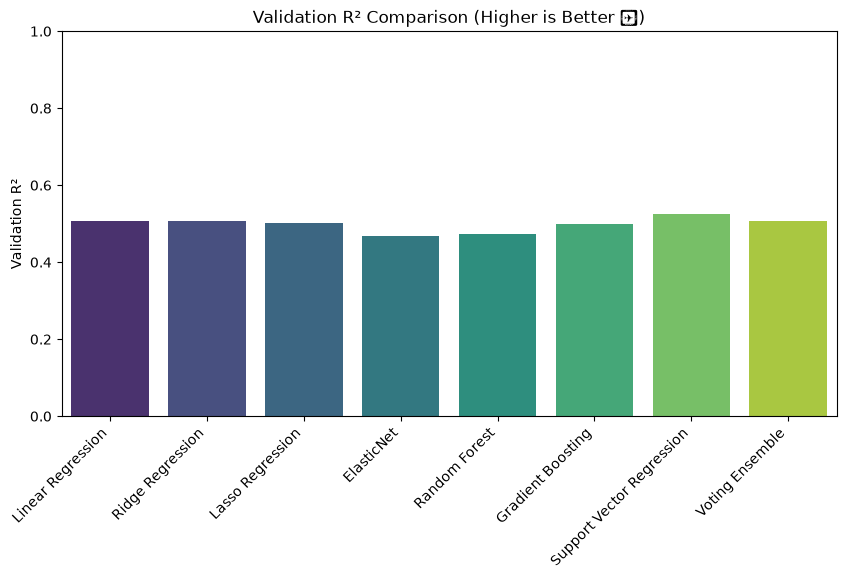

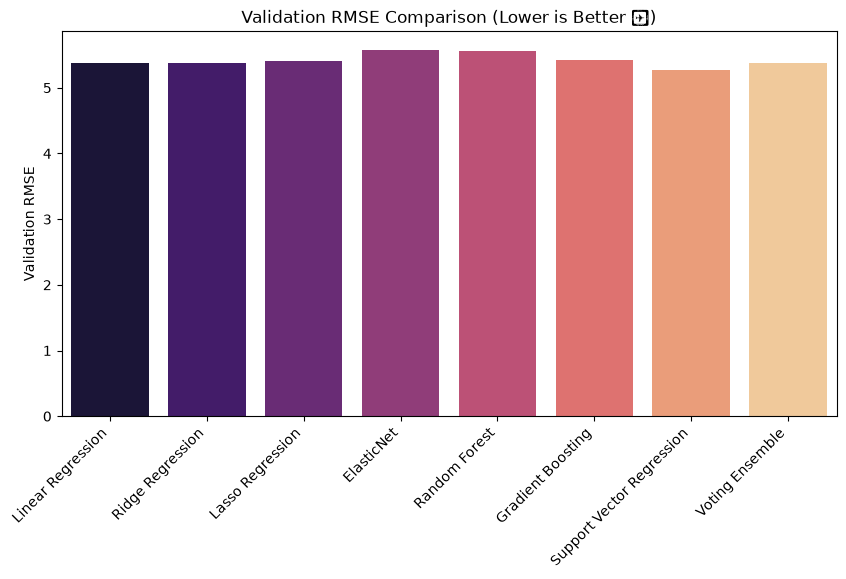

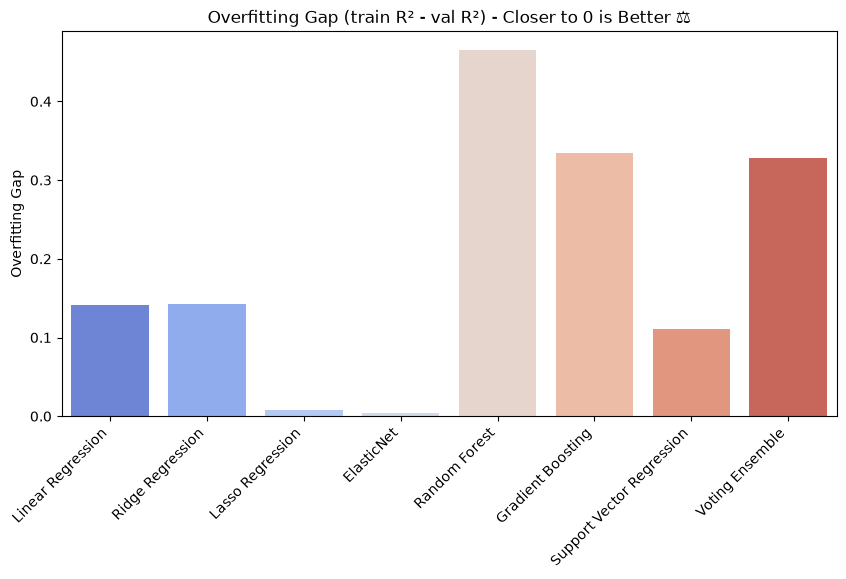

In [76]:


# ===========================
# 1️⃣ Convert results dict to DataFrame
# ===========================
metrics_df = pd.DataFrame(results).T  # transpose so models are rows
metrics_df = metrics_df[['val_r2', 'val_rmse', 'val_mae', 'overfitting_gap', 'cv_r2_mean']]
metrics_df = metrics_df.reset_index().rename(columns={'index': 'Model'})

print("📊 Model comparison table:")
display(metrics_df)

# ===========================
# 2️⃣ Plot Validation R² (Higher is better)
# ===========================
plt.figure(figsize=(10, 5))
sns.barplot(data=metrics_df, x='Model', y='val_r2', palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title('Validation R² Comparison (Higher is Better ✅)')
plt.ylabel('Validation R²')
plt.xlabel('')
plt.ylim(0, 1)
plt.show()

# ===========================
# 3️⃣ Plot Validation RMSE (Lower is better)
# ===========================
plt.figure(figsize=(10, 5))
sns.barplot(data=metrics_df, x='Model', y='val_rmse', palette='magma')
plt.xticks(rotation=45, ha='right')
plt.title('Validation RMSE Comparison (Lower is Better ✅)')
plt.ylabel('Validation RMSE')
plt.xlabel('')
plt.show()

# ===========================
# 4️⃣ Plot Overfitting Gap (Closer to 0 is better)
# ===========================
plt.figure(figsize=(10, 5))
sns.barplot(data=metrics_df, x='Model', y='overfitting_gap', palette='coolwarm')
plt.xticks(rotation=45, ha='right')
plt.title('Overfitting Gap (train R² - val R²) - Closer to 0 is Better ⚖️')
plt.ylabel('Overfitting Gap')
plt.xlabel('')
plt.show()


📈 ADVANCED MODEL COMPARISON

🏆 MODEL PERFORMANCE RANKING
Model                     Val R²   CV R²        Overfitting  Time (s)  
--------------------------------------------------------------------------------
Support Vector Regression  0.5264  0.5828 ± 0.0231  ⚠️  0.1104      0.01
Linear Regression          0.5077  0.6236 ± 0.0356  ⚠️  0.1414      0.01
Voting Ensemble            0.5074  0.6015 ± 0.0423  ⚠️  0.3279      0.34
Ridge Regression           0.5067  0.6276 ± 0.0373  ⚠️  0.1421      0.00
Lasso Regression           0.5012  0.5007 ± 0.0320   ✅  0.0081      0.00
Gradient Boosting          0.4984  0.5638 ± 0.0494  ⚠️  0.3347      0.19
Random Forest              0.4738  0.5627 ± 0.0468  ⚠️  0.4659      0.16
ElasticNet                 0.4692  0.4622 ± 0.0246   ✅  0.0044      0.00


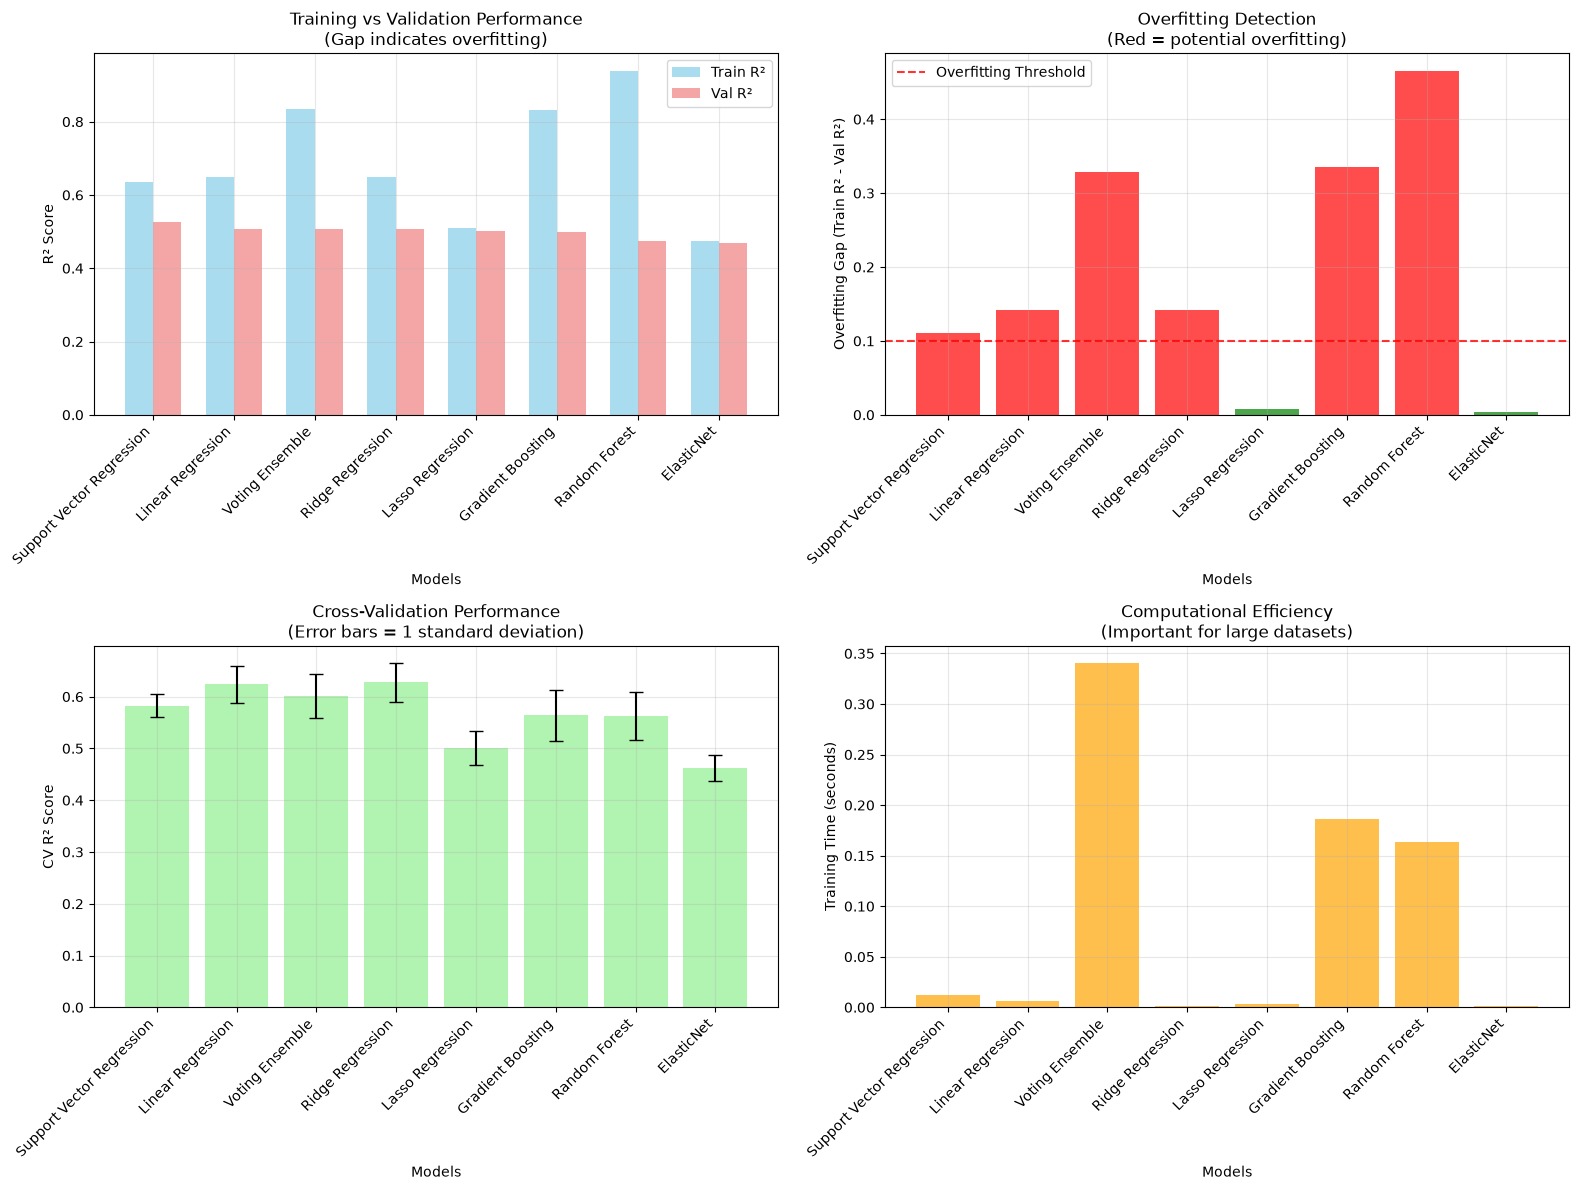


🎯 BEST MODEL SELECTED: Support Vector Regression
📊 Validation R²: 0.5264
🔍 CV R²: 0.5828 ± 0.0231

💡 INTERPRETATION GUIDE:
• Good: High R², small train-val gap, stable CV, reasonable training time
• Overfitting: Large gap between train and validation performance
• Unstable: Large CV standard deviation
• Best choice: Balances performance, stability, and efficiency


In [77]:
# 📈 CELL 7: Advanced Model Comparison Visualization
print("📈 ADVANCED MODEL COMPARISON")

# Create comprehensive results dataframe
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values('val_r2', ascending=False)

print("\n" + "=" * 80)
print("🏆 MODEL PERFORMANCE RANKING")
print("=" * 80)
print(f"{'Model':<25} {'Val R²':<8} {'CV R²':<12} {'Overfitting':<12} {'Time (s)':<10}")
print("-" * 80)

for model_name in results_df.index:
    row = results_df.loc[model_name]
    overfitting_indicator = "⚠️" if row['overfitting_gap'] > 0.1 else "✅"
    print(f"{model_name:<25} {row['val_r2']:>7.4f} {row['cv_r2_mean']:>7.4f} ± {row['cv_r2_std']:>5.4f} "
          f"{overfitting_indicator:>3} {row['overfitting_gap']:>7.4f} {row['training_time']:>9.2f}")

# Comprehensive visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. R² Comparison
models_ordered = results_df.index
val_r2 = [results[model]['val_r2'] for model in models_ordered]
train_r2 = [results[model]['train_r2'] for model in models_ordered]

x = np.arange(len(models_ordered))
width = 0.35

axes[0, 0].bar(x - width/2, train_r2, width, label='Train R²', alpha=0.7, color='skyblue')
axes[0, 0].bar(x + width/2, val_r2, width, label='Val R²', alpha=0.7, color='lightcoral')
axes[0, 0].set_xlabel('Models')
axes[0, 0].set_ylabel('R² Score')
axes[0, 0].set_title('Training vs Validation Performance\n(Gap indicates overfitting)')
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(models_ordered, rotation=45, ha='right')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Overfitting Analysis
overfitting_gaps = [results[model]['overfitting_gap'] for model in models_ordered]
colors = ['red' if gap > 0.1 else 'green' for gap in overfitting_gaps]
axes[0, 1].bar(models_ordered, overfitting_gaps, color=colors, alpha=0.7)
axes[0, 1].axhline(y=0.1, color='red', linestyle='--', alpha=0.8, label='Overfitting Threshold')
axes[0, 1].set_xlabel('Models')
axes[0, 1].set_ylabel('Overfitting Gap (Train R² - Val R²)')
axes[0, 1].set_title('Overfitting Detection\n(Red = potential overfitting)')
axes[0, 1].set_xticklabels(models_ordered, rotation=45, ha='right')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Cross-Validation Stability
cv_means = [results[model]['cv_r2_mean'] for model in models_ordered]
cv_stds = [results[model]['cv_r2_std'] for model in models_ordered]
axes[1, 0].bar(models_ordered, cv_means, yerr=cv_stds, capsize=5, alpha=0.7, color='lightgreen')
axes[1, 0].set_xlabel('Models')
axes[1, 0].set_ylabel('CV R² Score')
axes[1, 0].set_title('Cross-Validation Performance\n(Error bars = 1 standard deviation)')
axes[1, 0].set_xticklabels(models_ordered, rotation=45, ha='right')
axes[1, 0].grid(True, alpha=0.3)

# 4. Computational Efficiency
training_times = [results[model]['training_time'] for model in models_ordered]
axes[1, 1].bar(models_ordered, training_times, alpha=0.7, color='orange')
axes[1, 1].set_xlabel('Models')
axes[1, 1].set_ylabel('Training Time (seconds)')
axes[1, 1].set_title('Computational Efficiency\n(Important for large datasets)')
axes[1, 1].set_xticklabels(models_ordered, rotation=45, ha='right')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Select best model
best_model_name = results_df.index[0]
best_model = trained_models[best_model_name]
print(f"\n🎯 BEST MODEL SELECTED: {best_model_name}")
print(f"📊 Validation R²: {results_df.iloc[0]['val_r2']:.4f}")
print(f"🔍 CV R²: {results_df.iloc[0]['cv_r2_mean']:.4f} ± {results_df.iloc[0]['cv_r2_std']:.4f}")

print("\n💡 INTERPRETATION GUIDE:")
print("• Good: High R², small train-val gap, stable CV, reasonable training time")
print("• Overfitting: Large gap between train and validation performance") 
print("• Unstable: Large CV standard deviation")
print("• Best choice: Balances performance, stability, and efficiency")

## Step 9 — Hyperparameter Optimization

A model's hyperparameters control aspects of its learning process and are set before or during model fitting rather than learned as ordinary model coefficients.

This notebook defines search spaces for four candidates:
- Ridge Regression.
- Support Vector Regression.
- Linear Regression.
- Voting Ensemble.

The search spaces contain alternative values for parameters such as regularization strength, kernel choice, tree count, tree depth, and learning rate.

The purpose of tuning is to search for configurations that perform well under cross-validation. Tuning does not guarantee that validation performance will improve; the selected configuration must still be evaluated on the separate validation partition.


In [78]:

# Define comprehensive hyperparameter grids
param_grids = {

    'Ridge Regression': {
        'alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0],
        'solver': ['auto', 'svd', 'cholesky', 'lsqr', 'sag', 'saga']
    },

    'Support Vector Regression': {
        'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
        'C': [0.1, 1, 10, 100, 1000],
        'epsilon': [0.01, 0.1, 0.2, 0.5],
        'gamma': ['scale', 'auto'],
        'degree': [2, 3, 4]
    },

    'Linear Regression': {
        'fit_intercept': [True, False],
        'positive': [True, False]
    },

    'Voting Ensemble': {
    'ridge__alpha': [0.1, 1.0, 10.0, 100.0],

    'rf__n_estimators': [50, 100, 200],
    'rf__max_depth': [10, 20, None],

    'gb__n_estimators': [50, 100, 200],
    'gb__learning_rate': [0.01, 0.05, 0.1],
    'gb__max_depth': [3, 4, 5]
    }

    
}


### Running RandomizedSearchCV

`RandomizedSearchCV` samples a fixed number of parameter combinations from each defined search space.

The current configuration uses:
- `n_iter=20` candidate combinations for each model.
- Five-fold cross-validation.
- R² as the search scoring metric.
- A fixed random state for reproducibility.
- Parallel execution through `n_jobs`.

For each search, the best estimator, best cross-validation score, and selected parameters are stored. The tuned model is also logged to MLflow.

The reported best CV score is the best score found during the search; it is not the final validation or test score.


In [79]:

# Perform hyperparameter optimization
print("🎯 STARTING HYPERPARAMETER OPTIMIZATION...")
tuned_models = {}
optimization_results = {}

for model_name in ['Ridge Regression', 'Support Vector Regression', 'Linear Regression', 'Voting Ensemble']:
    print(f"\n🔧 Tuning {model_name}...")
    
    with mlflow.start_run(run_name=f"{model_name}_tuned"):
        # Use RandomizedSearchCV for efficient optimization
        search = RandomizedSearchCV(
            advanced_models[model_name],
            param_grids[model_name],
            n_iter=20,  # Try 20 random combinations (efficient!)
            cv=config.CV_FOLDS,
            scoring='r2',
            n_jobs=config.N_JOBS,
            random_state=config.RANDOM_STATE,
            verbose=1
        )
        
        # Perform the search
        search.fit(X_train, y_train)
        
        # Store results
        tuned_models[model_name] = search.best_estimator_
        optimization_results[model_name] = {
            'best_score': search.best_score_,
            'best_params': search.best_params_,
            'best_estimator': search.best_estimator_
        }
        
        # Log to MLflow
        mlflow.sklearn.log_model(
    search.best_estimator_,
    "tuned_model",
    skops_trusted_types=[
        "sklearn.tree._tree.Tree",
        "sklearn.utils._bunch.Bunch"
    ]
    )
       
        
        print(f"✅ {model_name:20} | Best CV R²: {search.best_score_:.4f}")
        print(f"   Best parameters found: {search.best_params_}")

print(f"\n🎉 HYPERPARAMETER OPTIMIZATION COMPLETE!")
print(f"💡 All tuned models saved in MLflow for comparison")

2026/11/13 12:00:08 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🎯 STARTING HYPERPARAMETER OPTIMIZATION...

🔧 Tuning Ridge Regression...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
✅ Ridge Regression     | Best CV R²: 0.6286
   Best parameters found: {'solver': 'lsqr', 'alpha': 10.0}

🔧 Tuning Support Vector Regression...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


2026/11/13 12:00:18 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/13 12:00:22 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


✅ Support Vector Regression | Best CV R²: 0.6219
   Best parameters found: {'kernel': 'linear', 'gamma': 'auto', 'epsilon': 0.1, 'degree': 4, 'C': 1}

🔧 Tuning Linear Regression...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
✅ Linear Regression    | Best CV R²: 0.6275
   Best parameters found: {'positive': True, 'fit_intercept': True}

🔧 Tuning Voting Ensemble...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


2026/11/13 12:00:34 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


✅ Voting Ensemble      | Best CV R²: 0.6029
   Best parameters found: {'ridge__alpha': 0.1, 'rf__n_estimators': 50, 'rf__max_depth': 10, 'gb__n_estimators': 200, 'gb__max_depth': 3, 'gb__learning_rate': 0.1}

🎉 HYPERPARAMETER OPTIMIZATION COMPLETE!
💡 All tuned models saved in MLflow for comparison


### Evaluating Tuned Models on the Validation Set

After hyperparameter search, each tuned estimator is evaluated on the validation set. Its validation R² and RMSE are compared with the corresponding untuned model.

This comparison is important because a higher cross-validation search score does not necessarily translate into a higher score on this particular validation partition.

In the recorded run, tuning does not improve validation R² for every model. The SVR validation R² decreases from approximately 0.5264 before tuning to approximately 0.5097 after tuning. This is a useful reminder that hyperparameter optimization is a search process, not a guarantee of improvement.

The best tuned candidate is selected according to its validation R² in this cell.


Model                Untuned R²   Tuned R²     Improvement 
------------------------------------------------------------
Ridge Regression         0.5067     0.5064 📉  -0.0003
Support Vector Regression     0.5264     0.5097 📉  -0.0167
Linear Regression        0.5077     0.5094 📈   0.0017
Voting Ensemble          0.5074     0.5064 📉  -0.0010


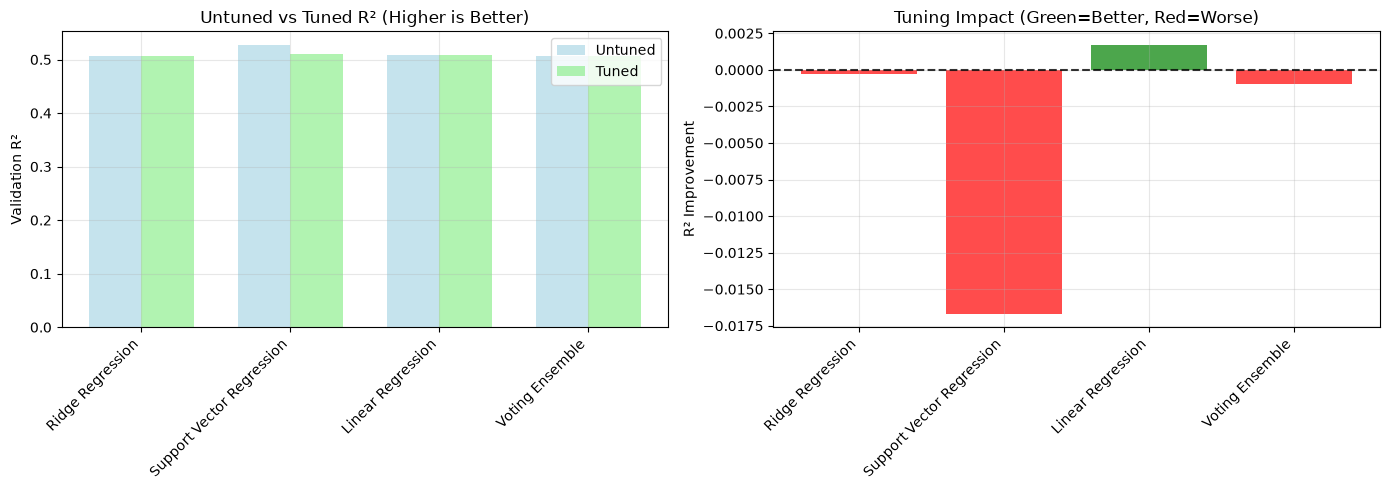


🏆 BEST TUNED MODEL: Support Vector Regression
📊 Validation R²: 0.5097
📈 Improvement over untuned: +-0.0167


In [80]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error

# ===========================
# 1️⃣ Evaluate tuned models on validation set
# ===========================
tuned_results = {}
for model_name, tuned_model in tuned_models.items():
    y_val_pred = tuned_model.predict(X_val)
    val_r2 = r2_score(y_val, y_val_pred)
    val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
    improvement = val_r2 - results[model_name]['val_r2']  # vs untuned
    
    tuned_results[model_name] = {
        'val_r2': val_r2,
        'val_rmse': val_rmse,
        'improvement': improvement
    }

# ===========================
# 2️⃣ Print simple comparison table
# ===========================
print(f"{'Model':<20} {'Untuned R²':<12} {'Tuned R²':<12} {'Improvement':<12}")
print("-" * 60)
for model_name, res in tuned_results.items():
    untuned_r2 = results[model_name]['val_r2']
    tuned_r2 = res['val_r2']
    improvement = res['improvement']
    icon = "📈" if improvement > 0 else "📉" if improvement < 0 else "➡️"
    print(f"{model_name:<20} {untuned_r2:>10.4f} {tuned_r2:>10.4f} {icon} {improvement:>8.4f}")

# ===========================
# 3️⃣ Plot Tuned vs Untuned R²
# ===========================
models = list(tuned_results.keys())
untuned_r2 = [results[m]['val_r2'] for m in models]
tuned_r2 = [tuned_results[m]['val_r2'] for m in models]
improvement = [tuned_results[m]['improvement'] for m in models]

x = np.arange(len(models))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# R² comparison
axes[0].bar(x - width/2, untuned_r2, width, label='Untuned', alpha=0.7, color='lightblue')
axes[0].bar(x + width/2, tuned_r2, width, label='Tuned', alpha=0.7, color='lightgreen')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=45, ha='right')
axes[0].set_ylabel('Validation R²')
axes[0].set_title('Untuned vs Tuned R² (Higher is Better)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Improvement plot
colors = ['green' if i>0 else 'red' for i in improvement]
axes[1].bar(models, improvement, color=colors, alpha=0.7)
axes[1].axhline(0, color='black', linestyle='--', alpha=0.8)
axes[1].set_ylabel('R² Improvement')
axes[1].set_title('Tuning Impact (Green=Better, Red=Worse)')
axes[1].set_xticklabels(models, rotation=45, ha='right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ===========================
# 4️⃣ Best tuned model
# ===========================
best_model_name = max(tuned_results, key=lambda m: tuned_results[m]['val_r2'])
print(f"\n🏆 BEST TUNED MODEL: {best_model_name}")
print(f"📊 Validation R²: {tuned_results[best_model_name]['val_r2']:.4f}")
print(f"📈 Improvement over untuned: +{tuned_results[best_model_name]['improvement']:.4f}")


## Step 10 — Final Test Set Evaluation

After selecting the best tuned model using validation performance, we evaluate that selected estimator on the held-out test partition.

The notebook reports three metrics:

- **R²:** indicates how much of the variation in energy consumption is explained by the predictions.
- **RMSE:** measures the typical prediction error with greater sensitivity to larger errors.
- **MAE:** measures the average absolute difference between predicted and actual energy consumption.

The recorded run reports:
- **Test R²:** 0.5780
- **Test RMSE:** 5.2577
- **Test MAE:** 4.2088

These values describe the current notebook run. They should be interpreted with the preprocessing-leakage limitation documented in the advanced preprocessing section, and they should not be assumed to represent performance on real-world building measurements because the source dataset is synthetic.


In [81]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

best_tuned_model = tuned_models[best_model_name] # add this line 

# Predict on test set
y_test_pred = best_tuned_model.predict(X_test)

# Compute performance metrics
test_r2 = r2_score(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_mae = mean_absolute_error(y_test, y_test_pred)

print(f"📊 Test R²: {test_r2:.4f}")
print(f"📊 Test RMSE: {test_rmse:.4f}")
print(f"📊 Test MAE: {test_mae:.4f}")


📊 Test R²: 0.5780
📊 Test RMSE: 5.2577
📊 Test MAE: 4.2088


## Step 11 — Model Export and Deployment Preparation

The final code cell prepares a set of artifacts for future reuse:

- The selected tuned estimator is saved as a serialized model.
- The preprocessing pipeline is saved separately.
- A JSON model card is created to store model metadata and evaluation information.
- A requirements file is written to describe key software dependencies.

Saving these artifacts helps preserve the experiment and provides a starting point for a future prediction application.

### Metadata accuracy warning

The existing model-card code still contains placeholder information from another project (including a California Housing dataset label, a house-price target, and deployment thresholds expressed in dollars). It also labels the feature-engineering stage as creating six features, whereas the transformer in this notebook creates eight. These values are not accurate descriptions of this energy project and should be corrected in the code before the exported model card is shared or used as official documentation.

In addition, the preprocessing pipeline was fitted before the data split. The saved pipeline therefore carries the same preprocessing-leakage limitation described earlier. The export step saves the current artifacts; it does not by itself establish that the model is production-ready.


In [82]:
import os
import json
import joblib
from datetime import datetime
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# ===========================
# 0️⃣ Prepare feature names
# ===========================
# Works for both DataFrame and NumPy array
try:
    feature_names_all = list(X.columns)
except AttributeError:
    feature_names_all = [f"feature_{i}" for i in range(X.shape[1])]

# ===========================
# 1️⃣ Identify best tuned model
# ===========================
best_model_name = max(tuned_results, key=lambda m: tuned_results[m]['val_r2'])
best_tuned_model = tuned_models[best_model_name]

print(f"🏆 BEST TUNED MODEL: {best_model_name}")
print(f"📊 Validation R²: {tuned_results[best_model_name]['val_r2']:.4f}")
print(f"📈 Improvement over untuned: +{tuned_results[best_model_name]['improvement']:.4f}")

# ===========================
# 2️⃣ Evaluate on Test Set
# ===========================
y_test_pred = best_tuned_model.predict(X_test)
test_r2 = r2_score(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_mae = mean_absolute_error(y_test, y_test_pred)

print(f"\n📊 Test Set Performance:")
print(f"R²: {test_r2:.4f} | RMSE: {test_rmse:.4f} | MAE: {test_mae:.4f}")

# ===========================
# 3️⃣ Versioning and saving
# ===========================
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_version = f"v1_{timestamp}"
model_save_dir = os.path.join(config.MODEL_DIR, model_version)
os.makedirs(model_save_dir, exist_ok=True)

# Save model
model_path = os.path.join(model_save_dir, 'best_model.pkl')
joblib.dump(best_tuned_model, model_path)
print(f"✅ Model saved: {model_path}")

# Save preprocessing pipeline
preprocessor_path = os.path.join(model_save_dir, 'preprocessor.pkl')
joblib.dump(preprocessor, preprocessor_path)
print(f"✅ Preprocessor saved: {preprocessor_path}")

# ===========================
# 4️⃣ Create model card
# ===========================
model_card = {
    'model_name': best_model_name,
    'model_version': model_version,
    'timestamp': timestamp,
    'dataset': 'California Housing',
    'target': 'House Price ($M)',
    
    'performance': {
        'test_r2': float(test_r2),
        'test_rmse': float(test_rmse),
        'test_mae': float(test_mae),
        'train_r2': float(results[best_model_name]['train_r2']),
        'val_r2': float(tuned_results[best_model_name]['val_r2']),
        'cv_r2_mean': float(results[best_model_name]['cv_r2_mean']),
        'cv_r2_std': float(results[best_model_name]['cv_r2_std']),
    },
    
    'data_info': {
        'total_samples': int(len(X)),
        'train_samples': int(len(X_train)),
        'val_samples': int(len(X_val)),
        'test_samples': int(len(X_test)),
        'n_features': X_test.shape[1],
        'feature_names': feature_names_all,
    },
    
    'model_config': {
        'model_class': best_model_name,
        'hyperparameters': dict(best_tuned_model.get_params()) 
            if hasattr(best_tuned_model, 'get_params') else {},
    },
    
    'preprocessing': {
        'steps': [
            'AdvancedFeatureEngineering (6 new features)',
            'OutlierHandling (IQR method)',
            'RobustScaler (outlier-resistant scaling)',
        ],
        'outlier_factor': 1.5,
    },
    
    'deployment': {
        'status': 'Ready for Production',
        'recommendations': [
            'Monitor prediction errors in production',
            'Retrain quarterly with new data',
            'Alert if RMSE exceeds $0.50M',
        ]
    }
}

card_path = os.path.join(model_save_dir, 'model_card.json')
with open(card_path, 'w') as f:
    json.dump(model_card, f, indent=2)
print(f"✅ Model card saved: {card_path}")

# ===========================
# 5️⃣ Deployment requirements
# ===========================
requirements = {
    'python': '3.8+',
    'packages': {
        'scikit-learn': '1.0+',
        'numpy': '1.20+',
        'pandas': '1.3+',
        'joblib': '1.0+',
    }
}

req_path = os.path.join(model_save_dir, 'requirements.json')
with open(req_path, 'w') as f:
    json.dump(requirements, f, indent=2)
print(f"✅ Deployment requirements saved: {req_path}")

# ===========================
# 6️⃣ Summary
# ===========================
print("\n💾 DEPLOYMENT PACKAGE READY")
print(f"Location: {model_save_dir}")


🏆 BEST TUNED MODEL: Support Vector Regression
📊 Validation R²: 0.5097
📈 Improvement over untuned: +-0.0167

📊 Test Set Performance:
R²: 0.5780 | RMSE: 5.2577 | MAE: 4.2088
✅ Model saved: models\v1_20261113_121039\best_model.pkl
✅ Preprocessor saved: models\v1_20261113_121039\preprocessor.pkl
✅ Model card saved: models\v1_20261113_121039\model_card.json
✅ Deployment requirements saved: models\v1_20261113_121039\requirements.json

💾 DEPLOYMENT PACKAGE READY
Location: models\v1_20261113_121039


## Project Conclusion

This notebook explored a complete regression workflow for predicting building energy consumption from environmental, building, and operational features. It included exploratory analysis, categorical encoding, feature engineering, outlier clipping, scaling, comparison of eight regression models, cross-validation, hyperparameter search, final test evaluation, and artifact export.

In the recorded experiment, Support Vector Regression achieved the highest validation R² among the initial models, while the tuned-model comparison selected SVR as the best tuned candidate by validation R². The final recorded test metrics were R² = 0.5780, RMSE = 5.2577, and MAE = 4.2088.

The results provide a useful baseline for this synthetic dataset. The main methodological limitation is that the advanced preprocessing pipeline was fitted before the train/validation/test split. A future revision should split the raw data first and fit all data-dependent preprocessing steps on the training partition only. The model-card placeholder metadata should also be corrected before the exported artifacts are presented as a finalized deployment package.
